#Statistical Modelling and Model Selection



In [5]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn statsmodels

In [6]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

In [7]:
# adjust this file path as required depending on the local directory structure
POSSIBLE_PATHS = [
    Path("/content/london_housing_feature_engineered.csv"),
    Path("/mnt/data/london_housing_feature_engineered.csv"),
    Path("/london_housing_feature_engineered.csv"),
]

DATA_PATH = next((p for p in POSSIBLE_PATHS if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Upload london_housing_feature_engineered.csv or update POSSIBLE_PATHS."
    )

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("File:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

File: /london_housing_feature_engineered.csv
Shape: (7375, 61)


,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter,month_gap,month_name,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,crime_lag_1,crime_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_3,price_rolling_std_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,price_mom_growth_pct,price_3m_growth_pct,price_yoy_growth_pct,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,houses_sold_mom_growth_pct,houses_sold_yoy_growth_pct,houses_sold_mom_growth_lag_1,houses_sold_yoy_growth_lag_1,real_price_2015,real_price_lag_1,real_price_lag_12,real_price_rolling_mean_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m,bank_rate_change_12m,bank_rate_change_1m_lag_1,bank_rate_change_12m_lag_1,post_2008,pandemic_2020
0,2001-01-01,barking and dagenham,82343,E09000002,215.0,1771.0,1,66.179174,2.708460,-0.633005,6.000000,2001,1,1,NaN,Jan,1,0.500000,8.660254e-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,124424.339313,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
1,2001-02-01,barking and dagenham,83266,E09000002,238.0,1600.0,1,66.522325,2.678571,0.518519,5.812500,2001,2,1,31.0,Feb,2,0.866025,5.000000e-01,82343.0,NaN,NaN,NaN,215.0,NaN,NaN,1771.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.120921,NaN,NaN,NaN,NaN,NaN,10.697674,NaN,NaN,NaN,125170.008226,124424.339313,NaN,NaN,66.179174,NaN,NaN,6.000000,NaN,NaN,-0.187500,NaN,NaN,NaN,0,0
2,2001-03-01,barking and dagenham,84058,E09000002,274.0,1759.0,1,66.600760,2.258016,0.117907,5.750000,2001,3,1,28.0,Mar,3,1.000000,6.123234e-17,83266.0,NaN,NaN,NaN,238.0,NaN,NaN,1600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.951169,NaN,NaN,1.120921,NaN,NaN,15.126050,NaN,10.697674,NaN,126211.773281,125170.008226,NaN,NaN,66.522325,NaN,NaN,5.812500,NaN,NaN,-0.062500,NaN,-0.187500,NaN,0,0
3,2001-04-01,barking and dagenham,83965,E09000002,241.0,1643.0,1,66.953715,1.773472,0.529957,5.533333,2001,4,2,31.0,Apr,4,0.866025,-5.000000e-01,84058.0,82343.0,NaN,NaN,274.0,215.0,NaN,1759.0,NaN,83222.333333,NaN,NaN,858.333463,NaN,242.333333,NaN,-0.110638,1.969809,NaN,0.951169,NaN,NaN,-12.043796,NaN,15.126050,NaN,125407.528859,126211.773281,NaN,NaN,66.600760,66.179174,NaN,5.750000,6.0000,NaN,-0.216667,NaN,-0.062500,NaN,0,0
4,2001-05-01,barking and dagenham,85124,E09000002,283.0,1809.0,1,67.375301,2.049302,0.629668,5.322581,2001,5,2,30.0,May,5,0.500000,-8.660254e-01,83965.0,83266.0,NaN,NaN,241.0,238.0,NaN,1643.0,NaN,83763.000000,NaN,NaN,432.919161,NaN,251.000000,NaN,1.380337,2.231403,NaN,-0.110638,1.969809,NaN,17.427386,NaN,-12.043796,NaN,126343.034291,125407.528859,NaN,NaN,66.953715,66.522325,NaN,5.533333,5.8125,NaN,-0.210753,NaN,-0.216667,NaN,0,0


In [ ]:
required_base_columns = {
    "date", "area", "average_price", "houses_sold"
}
#checking that the variables required for modelling actually exist
missing_base = sorted(required_base_columns.difference(df.columns))

if missing_base:
    raise ValueError(f"Missing required base columns: {missing_base}")

print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique areas:", df["area"].nunique())
print("Duplicate area-month rows:", df.duplicated(["area", "date"]).sum())
print("Missing dates:", df["date"].isna().sum())
print("Missing target values:", df["average_price"].isna().sum())

display(
    df[["average_price", "houses_sold"]]
    .describe()
    .T
)

Date range: 2001-01-01 00:00:00 to 2019-11-01 00:00:00
Unique areas: 33
Duplicate area-month rows: 0
Missing dates: 0
Missing target values: 0


,count,mean,std,min,25%,50%,75%,max
average_price,7375.0,348548.701424,188272.218176,82343.0,225163.0,296068.0,415970.0,1463378.0
houses_sold,7375.0,307.768000,140.912424,2.0,207.0,283.0,390.0,963.0


In [9]:
aggregate_areas = {
    "england", "london", "inner london", "outer london",
    "south east", "south west", "north east", "north west",
    "east midlands", "west midlands", "east of england",
    "yorks and the humber", "united kingdom"
}

work = df.copy()
work["area"] = work["area"].astype(str).str.strip()

if "borough_flag" in work.columns and work["borough_flag"].notna().any():
    borough_df = work.loc[work["borough_flag"].eq(1)].copy()
    filtering_method = "borough_flag == 1"
else:
    borough_df = work.loc[
        ~work["area"].str.lower().isin(aggregate_areas)
    ].copy()
    filtering_method = "known aggregate areas removed"

borough_df = (
    borough_df
    .dropna(subset=["date", "area", "average_price"])
    .drop_duplicates(["area", "date"])
    .sort_values(["area", "date"])
    .reset_index(drop=True)
)

print("Filtering method:", filtering_method)
print("Rows:", len(borough_df))
print("Areas:", borough_df["area"].nunique())
print(sorted(borough_df["area"].unique()))

Filtering method: borough_flag == 1
Rows: 7375
Areas: 33
['barking and dagenham', 'barnet', 'bexley', 'brent', 'bromley', 'camden', 'city of london', 'croydon', 'ealing', 'enfield', 'greenwich', 'hackney', 'hammersmith and fulham', 'haringey', 'harrow', 'havering', 'hillingdon', 'hounslow', 'islington', 'kensington and chelsea', 'kingston upon thames', 'lambeth', 'lewisham', 'merton', 'newham', 'redbridge', 'richmond upon thames', 'southwark', 'sutton', 'tower hamlets', 'waltham forest', 'wandsworth', 'westminster']


###  Rebuild leakage-safe features



Machine-learning models must not receive information from the future 
 
  create variables from historical information.

In [ ]:
g = borough_df.groupby("area", group_keys=False)

borough_df["year"] = borough_df["date"].dt.year
borough_df["month"] = borough_df["date"].dt.month
#Sine and cosine encode the month as a circle
borough_df["month_sin"] = np.sin(2 * np.pi * borough_df["month"] / 12)
borough_df["month_cos"] = np.cos(2 * np.pi * borough_df["month"] / 12)

min_date = borough_df["date"].min()
borough_df["time_index"] = (
    (borough_df["date"].dt.year - min_date.year) * 12
    + (borough_df["date"].dt.month - min_date.month)
)

for lag in [1, 3, 6, 12]:
    borough_df[f"price_lag_{lag}"] = g["average_price"].shift(lag)

for lag in [1, 3, 12]:
    borough_df[f"houses_sold_lag_{lag}"] = g["houses_sold"].shift(lag)

#This smooths short-term fluctuations
shifted_price = g["average_price"].shift(1)

borough_df["price_roll_mean_3"] = (
    shifted_price.groupby(borough_df["area"])
    .rolling(3).mean()
    .reset_index(level=0, drop=True)
)
borough_df["price_roll_mean_12"] = (
    shifted_price.groupby(borough_df["area"])
    .rolling(12).mean()
    .reset_index(level=0, drop=True)
)
borough_df["price_roll_std_12"] = (
    shifted_price.groupby(borough_df["area"])
    .rolling(12).std()
    .reset_index(level=0, drop=True)
)

#intended to capture historical growth or price momentum
borough_df["price_growth_yoy_lagged"] = (
    borough_df["price_lag_1"] / borough_df["price_lag_12"] - 1
)

#to use macroeconomic information that was already available rather than current/future information
if "cpi_lag_1" not in borough_df.columns:
    cpi_candidates = ["cpi_index_2015_100", "cpi"]
    cpi_source = next((c for c in cpi_candidates if c in borough_df.columns), None)
    if cpi_source:
        borough_df["cpi_lag_1"] = borough_df[cpi_source].shift(1)
#represents the recent interest-rate environment
if "bank_rate_lag_1" not in borough_df.columns:
    rate_candidates = ["bank_rate_monthly_avg", "bank_rate"]
    rate_source = next((c for c in rate_candidates if c in borough_df.columns), None)
    if rate_source:
        borough_df["bank_rate_lag_1"] = borough_df[rate_source].shift(1)

print("Feature engineering complete.")

Feature engineering complete.


In [ ]:
#remove first 12 months missing values and takes the first remaining value
sample_area = borough_df["area"].dropna().iloc[0]

display(
    borough_df.loc[
        borough_df["area"].eq(sample_area),
        [
            "date", "area", "average_price",
            "price_lag_1", "price_lag_12",
            "price_roll_mean_3", "price_roll_mean_12"
        ]
    ].head(16)
)

,date,area,average_price,price_lag_1,price_lag_12,price_roll_mean_3,price_roll_mean_12
0,2001-01-01,barking and dagenham,82343,NaN,NaN,NaN,NaN
1,2001-02-01,barking and dagenham,83266,82343.0,NaN,NaN,NaN
2,2001-03-01,barking and dagenham,84058,83266.0,NaN,NaN,NaN
3,2001-04-01,barking and dagenham,83965,84058.0,NaN,83222.333333,NaN
4,2001-05-01,barking and dagenham,85124,83965.0,NaN,83763.000000,NaN
5,2001-06-01,barking and dagenham,86732,85124.0,NaN,84382.333333,NaN
6,2001-07-01,barking and dagenham,89194,86732.0,NaN,85273.666667,NaN
7,2001-08-01,barking and dagenham,90462,89194.0,NaN,87016.666667,NaN
8,2001-09-01,barking and dagenham,92610,90462.0,NaN,88796.000000,NaN
9,2001-10-01,barking and dagenham,93584,92610.0,NaN,90755.333333,NaN




The first 12 months per borough are unavailable because a 12-month lag is required.  
Dropping them is expected and is not data loss caused by an error.

The main prediction models use available-at-forecast features.  
The macroeconomic variables are included only when present.

In [ ]:
numeric_features = [
    "price_lag_1",
    "price_lag_3",
    "price_lag_6",
    "price_lag_12",
    "houses_sold_lag_1",
    "houses_sold_lag_3",
    "houses_sold_lag_12",
    "price_roll_mean_3",
    "price_roll_mean_12",
    "price_roll_std_12",
    "price_growth_yoy_lagged",
    "time_index",
    "month_sin",
    "month_cos",
]

for optional_feature in ["cpi_lag_1", "bank_rate_lag_1"]:
    if optional_feature in borough_df.columns:
        numeric_features.append(optional_feature)

categorical_features = ["area"]
target = "average_price"

model_columns = [
    "date", "year", target, *categorical_features, *numeric_features
]
#creates a clean modelling dataset
model_df = (
    borough_df[model_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=[target, "price_lag_12"])
    .sort_values(["date", "area"])
    .reset_index(drop=True)
)

print("Model rows:", len(model_df))
print("Model date range:", model_df["date"].min(), "to", model_df["date"].max())
print("Features:", numeric_features + categorical_features)

Model rows: 6979
Model date range: 2002-01-01 00:00:00 to 2019-11-01 00:00:00
Features: ['price_lag_1', 'price_lag_3', 'price_lag_6', 'price_lag_12', 'houses_sold_lag_1', 'houses_sold_lag_3', 'houses_sold_lag_12', 'price_roll_mean_3', 'price_roll_mean_12', 'price_roll_std_12', 'price_growth_yoy_lagged', 'time_index', 'month_sin', 'month_cos', 'cpi_lag_1', 'bank_rate_lag_1', 'area']


###  Exploratory checks used before modelling

,count,mean,std,min,25%,50%,75%,max
average_price,6979.0,358291.486173,188244.635101,98713.000000,232664.500000,3.037400e+05,426088.500000,1.463378e+06
price_lag_1,6979.0,356750.758848,187937.900304,96712.000000,231595.000000,3.024070e+05,423951.000000,1.463378e+06
price_lag_3,6979.0,353620.113197,187269.090498,93584.000000,229371.500000,2.998660e+05,419151.500000,1.463378e+06
price_lag_6,6979.0,348901.986531,186073.012638,89194.000000,226810.500000,2.958440e+05,413000.500000,1.463378e+06
price_lag_12,6979.0,339256.998710,183676.763071,82343.000000,223026.500000,2.883970e+05,403086.000000,1.463378e+06
houses_sold_lag_1,6979.0,302.699384,138.529988,2.000000,205.000000,2.770000e+02,382.000000,9.630000e+02
houses_sold_lag_3,6979.0,304.894971,139.209294,2.000000,206.000000,2.800000e+02,386.000000,9.630000e+02
houses_sold_lag_12,6979.0,314.034389,141.205017,2.000000,214.000000,2.900000e+02,398.000000,9.630000e+02
price_roll_mean_3,6979.0,355189.968716,187517.400266,95404.666667,230441.000000,3.009057e+05,421495.333333,1.411622e+06
price_roll_mean_12,6979.0,348077.894242,185442.339518,88664.000000,227104.041667,2.957494e+05,411963.166667,1.365412e+06


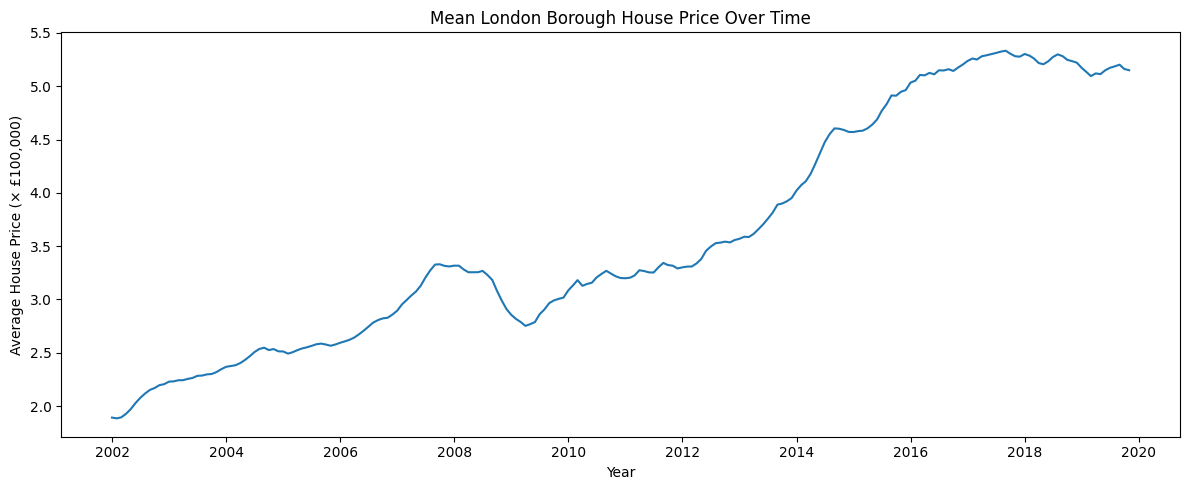

In [30]:
display(model_df[[target] + numeric_features].describe().T)

plt.figure(figsize=(12, 5))

monthly_mean = model_df.groupby("date")[target].mean()

plt.plot(
    monthly_mean.index,
    monthly_mean.values / 100000
)

plt.title("Mean London Borough House Price Over Time")

plt.xlabel("Year")
plt.ylabel("Average House Price (× £100,000)")

plt.tight_layout()

plt.show()

### Evaluation Metrics

For regression, there is no single valid accuracy percentage.

Main measure

- **MAE:** average absolute error in pound
- **RMSE:** penalises very large errors more heavily.
- **MAPE:** average percentage error; interpret cautiously when actual values are near zero.
- **R²:** proportion of variation explained, not percentage accuracy.
- **MAE improvement over baseline:** positive means the model beats the seasonal naive rule.

In [ ]:
#a function to calculate regression evaluation metrics
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAPE_pct": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred),
    }



### Model A — Seasonal naive baseline

Predict each borough's price using its price 12 months earlier.

### Model B — Ridge regression

A transparent regularised linear model with:

- borough one-hot encoding;
- standardised numerical variables;
- protection against unstable coefficients caused by multicollinearity.

### Model C — Random Forest

A nonlinear comparison model that can capture interactions and non-linear patterns.  
It is included after the simple model

In [ ]:
linear_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            #Median is more robust against extreme values
            #Standardising scales ensures predictors measured on different scales are treated fairly
            numeric_features,
        ),
        (
            "area",
            OneHotEncoder(handle_unknown="ignore"),
            #Models can't directly understand text,so converts them into 0,1 variables
            categorical_features,
        ),
    ]
)

ridge_model = Pipeline([
    ("preprocess", linear_preprocessor),
    ("model", Ridge(alpha=10.0))
])

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_features,
        ),
        (
            "area",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ],
    sparse_threshold=0
)

random_forest_model = Pipeline([
    ("preprocess", tree_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300, # decision trees 
        min_samples_leaf=3, #to reduce overfiting ,each final leaf in a tree must contain at least 3 training observations
        max_features=0.8, #80% of the available features when looking for splits to adds diversity between trees
        n_jobs=-1, #uses all available CPU cores, so training runs faster
        random_state=RANDOM_STATE
    ))
])

In [16]:
months_per_year = model_df.groupby("year")["date"].nunique()
complete_years = months_per_year[months_per_year.eq(12)].index.tolist()

minimum_training_months = 24
eligible_test_years = []

for year in complete_years:
    earlier_months = model_df.loc[
        model_df["year"].lt(year), "date"
    ].nunique()
    if earlier_months >= minimum_training_months:
        eligible_test_years.append(year)

print("Complete years:", complete_years)
print("Backtest years:", eligible_test_years)

if not eligible_test_years:
    raise ValueError("No year has 12 complete months plus sufficient training history.")

Complete years: [2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]
Backtest years: [2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]


### Expanding-window yearly backtest

For every test year

- training data contain only years before the test year;
- the model is refitted from scratch;
- the following year is predicted;
- the same test observations are used for every model;
- metrics are stored year by year.



In [ ]:
def expanding_window_backtest(
    data,
    test_years,
    ridge_pipeline,
    forest_pipeline,
    feature_columns,
    target_column="average_price"
):
    annual_results = []
    prediction_frames = []

    X_columns = feature_columns + ["area"]

    for test_year in test_years:
        train = data.loc[data["year"].lt(test_year)].copy()
        test = data.loc[data["year"].eq(test_year)].copy()

        test = test.dropna(subset=["price_lag_12", target_column]).copy()

        if train.empty or test.empty:
            continue

        X_train = train[X_columns]
        y_train = train[target_column]
        X_test = test[X_columns]
        y_test = test[target_column]

        predictions = {
            "Seasonal naive": test["price_lag_12"].to_numpy()
        }

        #Model is refitted every year to gets a newly trained model
        # Ridge
        ridge_pipeline.fit(X_train, y_train)
        predictions["Ridge regression"] = ridge_pipeline.predict(X_test)

        # Random Forest
        forest_pipeline.fit(X_train, y_train)
        predictions["Random Forest"] = forest_pipeline.predict(X_test)

        baseline_mae = mean_absolute_error(
            y_test, predictions["Seasonal naive"]
        )

        for model_name, y_pred in predictions.items():
            metrics = regression_metrics(y_test, y_pred)
            metrics.update({
                "test_year": test_year,
                "model": model_name,
                "train_start": train["date"].min(),
                "train_end": train["date"].max(),
                "n_train": len(train),
                "n_test": len(test),
                "MAE_improvement_vs_baseline_pct": (
                    (baseline_mae - metrics["MAE"]) / baseline_mae * 100
                )
            })
            annual_results.append(metrics)

            pred_frame = test[
                ["date", "year", "area", target_column]
            ].copy()
            pred_frame["model"] = model_name
            pred_frame["prediction"] = y_pred
            pred_frame["absolute_error"] = np.abs(
                pred_frame[target_column] - pred_frame["prediction"]
            )
            prediction_frames.append(pred_frame)

        print(
            f"Completed {test_year}: "
            f"train={len(train):,}, test={len(test):,}"
        )

    return (
        pd.DataFrame(annual_results),
        pd.concat(prediction_frames, ignore_index=True)
    )

annual_results, all_predictions = expanding_window_backtest(
    data=model_df,
    test_years=eligible_test_years,
    ridge_pipeline=ridge_model,
    forest_pipeline=random_forest_model,
    feature_columns=numeric_features,
    target_column=target
)

display(annual_results.head(9))

Completed 2004: train=792, test=396
Completed 2005: train=1,188, test=396
Completed 2006: train=1,584, test=396
Completed 2007: train=1,980, test=396
Completed 2008: train=2,376, test=396
Completed 2009: train=2,772, test=396
Completed 2010: train=3,168, test=387
Completed 2011: train=3,555, test=384
Completed 2012: train=3,939, test=384
Completed 2013: train=4,323, test=384
Completed 2014: train=4,707, test=384
Completed 2015: train=5,091, test=384
Completed 2016: train=5,475, test=384
Completed 2017: train=5,859, test=384
Completed 2018: train=6,243, test=384


,MAE,RMSE,MAPE_pct,R2,test_year,model,train_start,train_end,n_train,n_test,MAE_improvement_vs_baseline_pct
0,19425.790404,22357.884733,7.806714,0.898815,2004,Seasonal naive,2002-01-01,2003-12-01,792,396,0.000000
1,10562.117902,12973.965370,4.398691,0.965928,2004,Ridge regression,2002-01-01,2003-12-01,792,396,45.628375
2,4335.244684,9844.164445,1.418544,0.980384,2004,Random Forest,2002-01-01,2003-12-01,792,396,77.683046
3,9328.815657,12308.148027,3.564075,0.970913,2005,Seasonal naive,2002-01-01,2004-12-01,1188,396,0.000000
4,3333.390760,5380.505456,1.205016,0.994441,2005,Ridge regression,2002-01-01,2004-12-01,1188,396,64.267803
5,4694.760431,7296.591576,1.674782,0.989778,2005,Random Forest,2002-01-01,2004-12-01,1188,396,49.674636
6,17784.133838,23941.119147,5.905331,0.920713,2006,Seasonal naive,2002-01-01,2005-12-01,1584,396,0.000000
7,3875.596303,5922.647916,1.300345,0.995148,2006,Ridge regression,2002-01-01,2005-12-01,1584,396,78.207562
8,4716.508393,12137.277865,1.314577,0.979622,2006,Random Forest,2002-01-01,2005-12-01,1584,396,73.479122




The pooled metrics below are calculated from all yearly holdout predictions.  


In [ ]:
#Model Comparison
overall_results = (
    all_predictions
    .groupby("model", group_keys=False)
    .apply(
        lambda x: pd.Series(
            regression_metrics(x[target], x["prediction"])
        ),
        include_groups=False
    )
    .reset_index()
)

#find the role =  Seasonal naive
baseline_overall_mae = overall_results.loc[
    overall_results["model"].eq("Seasonal naive"), "MAE"
].iloc[0]

#calculate improvement over baseline -How much lower % is each model's MAE compared with Seasonal Naive? 
overall_results["MAE_improvement_vs_baseline_pct"] = (
    (baseline_overall_mae - overall_results["MAE"])
    / baseline_overall_mae * 100
)
#rank the models
overall_results = overall_results.sort_values("MAE")
display(overall_results.style.format({
    "MAE": "£{:,.0f}",
    "RMSE": "£{:,.0f}",
    "MAPE_pct": "{:.2f}%",
    "R2": "{:.3f}",
    "MAE_improvement_vs_baseline_pct": "{:.2f}%"
}))

,model,MAE,RMSE,MAPE_pct,R2,MAE_improvement_vs_baseline_pct
1,Ridge regression,"£6,978","£11,191",1.95%,0.996,75.02%
0,Random Forest,"£7,339","£17,353",1.61%,0.991,73.73%
2,Seasonal naive,"£27,936","£38,099",7.55%,0.959,0.00%


Compare Ridge, Random Forest and Seasonal Naive year by year using expanding-window MAE

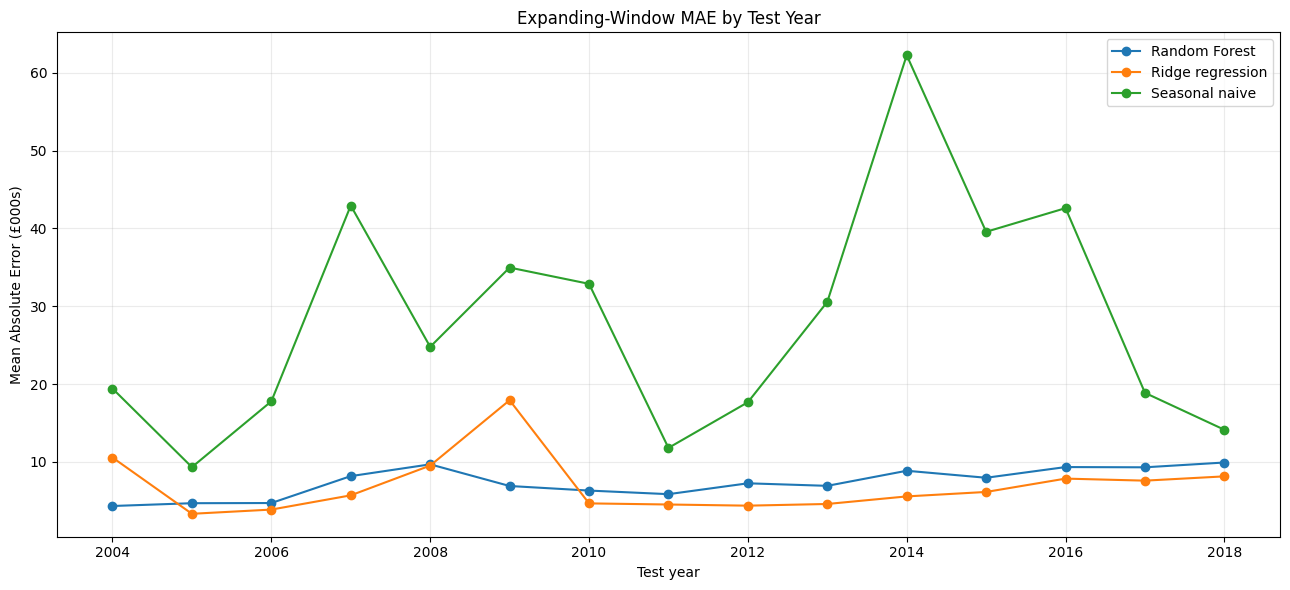

In [ ]:
from matplotlib.ticker import FuncFormatter
#customise how numbers appear on the graph axis
plt.figure(figsize=(13, 6))

for model_name, group in annual_results.groupby("model"):
    group = group.sort_values("test_year")
    plt.plot(
        group["test_year"], #X-axis
        group["MAE"],       #Y-axis
        marker="o",         #puts a circle on each yearly result
        label=model_name
    )

#chnage into thousands of pounds
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value / 1000:,.0f}")
)

plt.title("Expanding-Window MAE by Test Year")
plt.xlabel("Test year")
plt.ylabel("Mean Absolute Error (£000s)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()



Ridge Regression achieved lower prediction errors across most test years and was therefore selected as the primary forecasting model. Random Forest, however, showed less year-to-year variability in MAE, indicating greater stability. The choice therefore represents a trade-off between slightly higher predictive accuracy from Ridge and greater consistency from Random Forest.

Creates a table of MAE values by year and by model

In [20]:
mae_pivot = annual_results.pivot(
    index="test_year",
    columns="model",
    values="MAE"
)

display(
    mae_pivot.style.format("£{:,.0f}")
)

model,Random Forest,Ridge regression,Seasonal naive
test_year,,,
2004,"£4,335","£10,562","£19,426"
2005,"£4,695","£3,333","£9,329"
2006,"£4,717","£3,876","£17,784"
2007,"£8,174","£5,704","£42,937"
2008,"£9,688","£9,529","£24,785"
2009,"£6,905","£17,927","£34,972"
2010,"£6,318","£4,671","£32,882"
2011,"£5,856","£4,527","£11,800"
2012,"£7,251","£4,378","£17,668"




A positive percentage means the model improved on the seasonal naive baseline.  
A negative percentage means the simple baseline was more accurate.

model,Random Forest,Ridge regression
test_year,,
2004,77.68%,45.63%
2005,49.67%,64.27%
2006,73.48%,78.21%
2007,80.96%,86.72%
2008,60.91%,61.55%
2009,80.25%,48.74%
2010,80.79%,85.80%
2011,50.37%,61.63%
2012,58.96%,75.22%


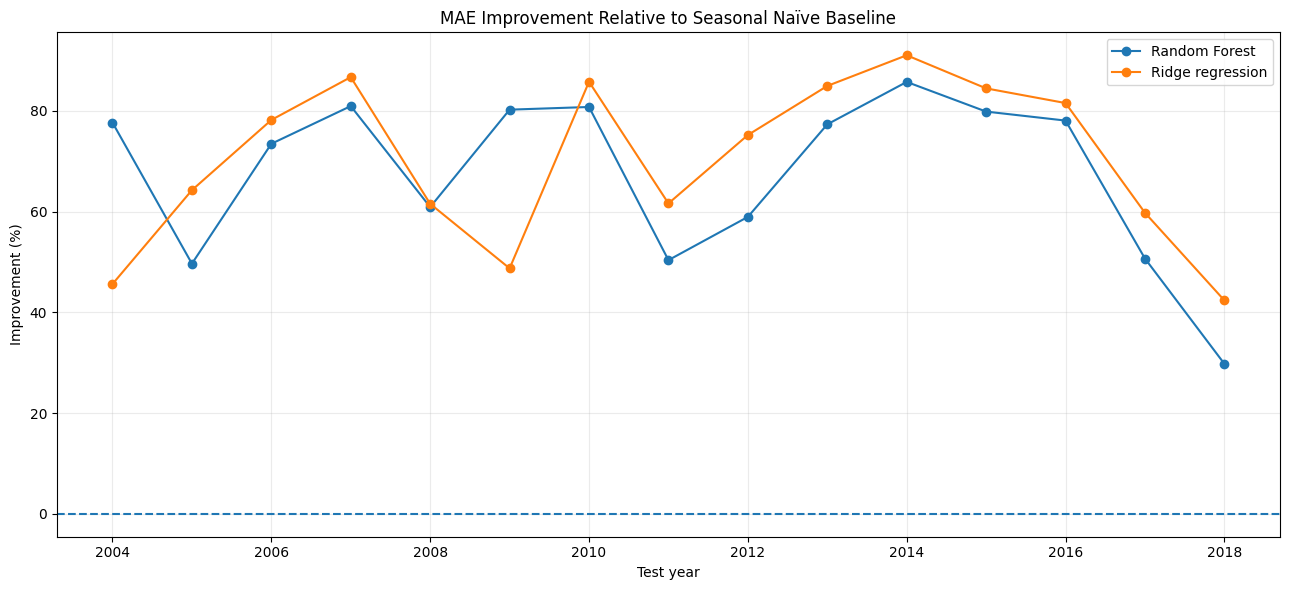

In [21]:
improvement_table = (
    annual_results
    .pivot(
        index="test_year",
        columns="model",
        values="MAE_improvement_vs_baseline_pct"
    )
    .drop(columns=["Seasonal naive"], errors="ignore")
)

display(improvement_table.style.format("{:.2f}%"))

plt.figure(figsize=(13, 6))
for model_name in improvement_table.columns:
    plt.plot(
        improvement_table.index,
        improvement_table[model_name],
        marker="o",
        label=model_name
    )

plt.axhline(0, linestyle="--")
plt.title("MAE Improvement Relative to Seasonal Naïve Baseline")
plt.xlabel("Test year")
plt.ylabel("Improvement (%)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [22]:
borough_results = (
    all_predictions
    .groupby(["model", "area"])
    .apply(
        lambda x: pd.Series(
            regression_metrics(x[target], x["prediction"])
        ),
        include_groups=False
    )
    .reset_index()
)

best_model_name = overall_results.iloc[0]["model"]
best_borough_results = (
    borough_results
    .loc[borough_results["model"].eq(best_model_name)]
    .sort_values("MAE", ascending=False)
)

print("Best pooled-MAE model:", best_model_name)
display(
    best_borough_results.head(10).style.format({
        "MAE": "£{:,.0f}",
        "RMSE": "£{:,.0f}",
        "MAPE_pct": "{:.2f}%",
        "R2": "{:.3f}"
    })
)

Best pooled-MAE model: Ridge regression


,model,area,MAE,RMSE,MAPE_pct,R2
52,Ridge regression,kensington and chelsea,"£27,903","£34,426",3.08%,0.987
39,Ridge regression,city of london,"£18,662","£23,643",5.01%,0.854
65,Ridge regression,westminster,"£15,649","£20,750",2.27%,0.992
38,Ridge regression,camden,"£11,879","£15,543",2.01%,0.992
45,Ridge regression,hammersmith and fulham,"£11,434","£14,552",2.14%,0.990
51,Ridge regression,islington,"£9,147","£11,709",2.10%,0.992
59,Ridge regression,richmond upon thames,"£8,195","£11,210",1.83%,0.992
64,Ridge regression,wandsworth,"£7,829","£9,731",1.99%,0.993
44,Ridge regression,hackney,"£7,137","£9,809",2.05%,0.993
60,Ridge regression,southwark,"£7,028","£9,135",2.20%,0.992


### Actual versus predicted values for the latest complete test year

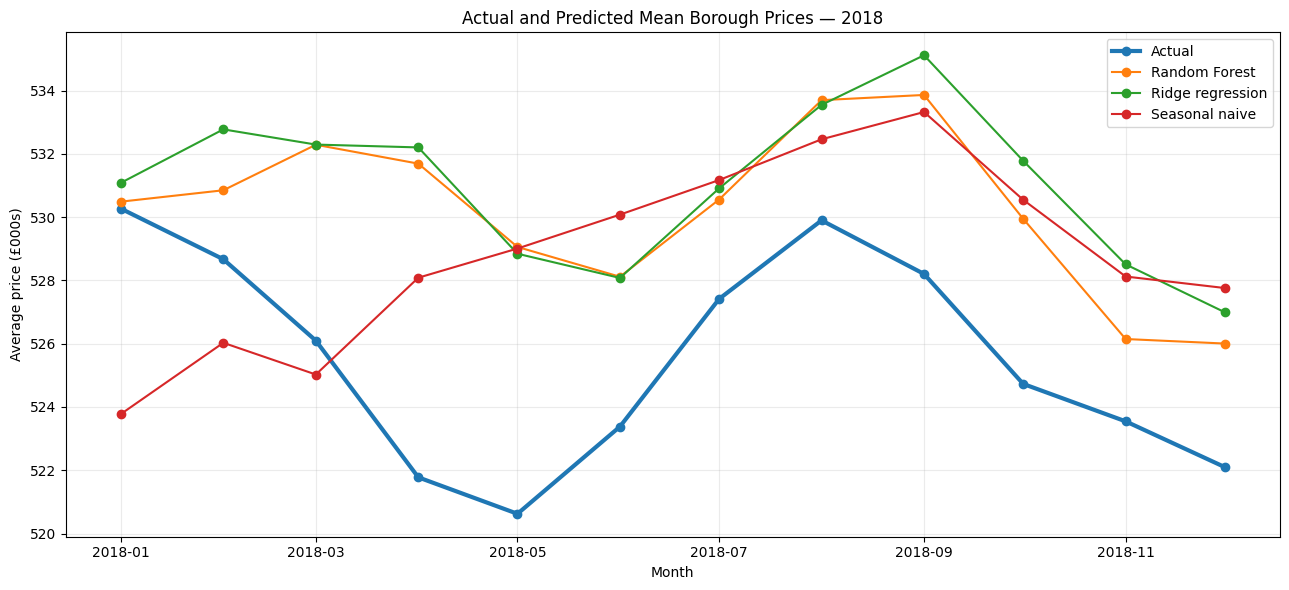

In [23]:
latest_test_year = max(eligible_test_years)

latest_predictions = all_predictions.loc[
    all_predictions["year"].eq(latest_test_year)
].copy()

monthly_latest = (
    latest_predictions
    .groupby(["model", "date"])
    .agg(
        actual_price=(target, "mean"),
        predicted_price=("prediction", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(13, 6))
actual_line = (
    monthly_latest[["date", "actual_price"]]
    .drop_duplicates()
    .sort_values("date")
)
plt.plot(
    actual_line["date"],
    actual_line["actual_price"],
    marker="o",
    linewidth=3,
    label="Actual"
)

for model_name, group in monthly_latest.groupby("model"):
    group = group.sort_values("date")
    plt.plot(
        group["date"],
        group["predicted_price"],
        marker="o",
        label=model_name
    )

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value / 1000:,.0f}")
)


plt.title(f"Actual and Predicted Mean Borough Prices — {latest_test_year}")
plt.xlabel("Month")
plt.ylabel("Average price (£000s)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

All models capture some of the general monthly changes, but none of them fully capture the size of the price fall in 2018.

This graph compares the actual and predicted average borough house prices for each month in 2018. The actual prices fall noticeably during the first half of the year, recover slightly during the summer, and then decrease again later in the year. The models follow some of these general movements, but they tend to predict higher prices than the actual values, especially during the spring decline. Since the graph shows average prices across all boroughs, it is mainly used as a visual check of model performance rather than as the main measure of forecasting accuracy.

###   Explanatory fixed-effects regression

This regression is retained as a separate explanatory analysis.  
It estimates conditional associations after controlling for persistent borough differences, trend and seasonality.


In [24]:
explanatory_terms = [
    "houses_sold_lag_1",
    "time_index",
    "month_sin",
    "month_cos"
]

for optional_feature in ["cpi_lag_1", "bank_rate_lag_1"]:
    if optional_feature in model_df.columns:
        explanatory_terms.append(optional_feature)

formula = (
    "np.log(average_price) ~ "
    + " + ".join(explanatory_terms)
    + " + C(area)"
)

explanatory_df = model_df.dropna(
    subset=["average_price", "area"] + explanatory_terms
).copy()

fixed_effect_model = smf.ols(
    formula=formula,
    data=explanatory_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": explanatory_df["area"]}
)

print(fixed_effect_model.summary())

                              OLS Regression Results                             
Dep. Variable:     np.log(average_price)   R-squared:                       0.969
Model:                               OLS   Adj. R-squared:                  0.969
Method:                    Least Squares   F-statistic:                 2.708e+04
Date:                   Tue, 01 Sep 2026   Prob (F-statistic):           7.82e-58
Time:                           15:57:59   Log-Likelihood:                 8103.4
No. Observations:                   6979   AIC:                        -1.613e+04
Df Residuals:                       6940   BIC:                        -1.586e+04
Df Model:                             38                                         
Covariance Type:                 cluster                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

###  Fixed-Effects Regression Residual Diagnostics


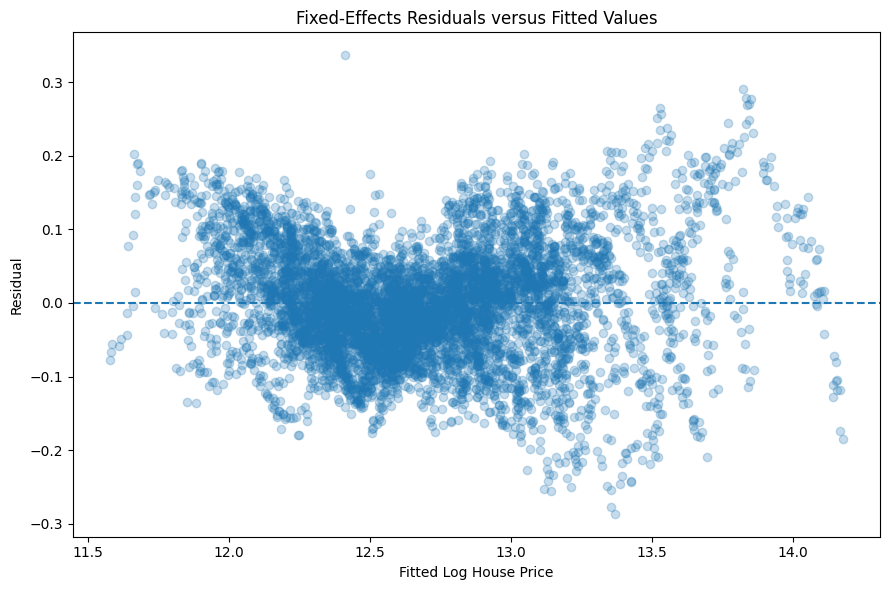

,0
Durbin_Watson,1.312270
Breusch_Pagan_LM,1694.426263
Breusch_Pagan_p_value,0.000000
Breusch_Pagan_F,58.558317
Breusch_Pagan_F_p_value,0.000000


In [ ]:
residuals = fixed_effect_model.resid #actual value − predicted value
fitted = fixed_effect_model.fittedvalues #values predicted by the fixed-effects model

plt.figure(figsize=(9, 6))
plt.scatter(fitted, residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.title("Fixed-Effects Residuals versus Fitted Values")
plt.xlabel("Fitted Log House Price")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

dw = durbin_watson(residuals)
#checks for heteroskedasticity
bp = het_breuschpagan(
    fixed_effect_model.resid,
    fixed_effect_model.model.exog
)

diagnostics = pd.Series({
    "Durbin_Watson": dw,
    "Breusch_Pagan_LM": bp[0],
    "Breusch_Pagan_p_value": bp[1],
    "Breusch_Pagan_F": bp[2],
    "Breusch_Pagan_F_p_value": bp[3],
})

display(diagnostics)

The Durbin-Watson statistic was approximately 1.31, suggesting some remaining positive temporal autocorrelation in the residuals so errors were somewhat related across time, so the residuals were not completely independent.

p value <0.05 normally reject the null hypothesis of constant variance and evidence of heteroskedasticity

  so residual variance is not constant

Ridge was the best forecasting model overall, but it still overpredicted prices in parts of 2018. The fixed-effects regression also showed non-random residual patterns, so I interpret its coefficients cautiously and do not claim that the variables directly caused house-price changes.

### CPI-trend multicollinearity check

CPI and a linear time trend may contain nearly the same long-run information.  
High VIF values mean individual coefficients can be unstable even when overall fit is high.



Variance Inflation Factor , to check explanatory variables were strongly related to each other

In [ ]:
vif_candidates = [
    c for c in [
        "houses_sold_lag_1",
        "cpi_lag_1",
        "bank_rate_lag_1",
        "time_index",
        "month_sin",
        "month_cos"
    ]
    if c in explanatory_df.columns
]

vif_matrix = (
    explanatory_df[vif_candidates]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

vif_results = pd.DataFrame({
    "variable": vif_candidates,
    "VIF": [
        variance_inflation_factor(vif_matrix.values, i)
        for i in range(vif_matrix.shape[1])
    ]
}).sort_values("VIF", ascending=False)

display(vif_results)

,variable,VIF
1,cpi_lag_1,60.103181
3,time_index,35.246909
0,houses_sold_lag_1,7.508069
2,bank_rate_lag_1,6.036433
4,month_sin,1.050695
5,month_cos,1.000586


strong multicollinearity mainly between CPI and the long-term time trend

seasonal variables showed no concern 

supported cautious coefficient interpretation and the use of Ridge regularisation.



final predictive model

- Lowest pooled expanding-window MAE.
- Positive and reasonably consistent improvement over the seasonal naive baseline.
- Acceptable RMSE and MAPE.
- Stability across test years and boroughs.
- Simplicity and interpretability when performance differences are small.


In [27]:
winner = overall_results.iloc[0]

print("Selected model:", winner["model"])
print(f"Pooled MAE: £{winner['MAE']:,.0f}")
print(f"Pooled RMSE: £{winner['RMSE']:,.0f}")
print(f"Pooled MAPE: {winner['MAPE_pct']:.2f}%")
print(f"Pooled R²: {winner['R2']:.3f}")
print(
    "MAE improvement versus baseline: "
    f"{winner['MAE_improvement_vs_baseline_pct']:.2f}%"
)

Selected model: Ridge regression
Pooled MAE: £6,978
Pooled RMSE: £11,191
Pooled MAPE: 1.95%
Pooled R²: 0.996
MAE improvement versus baseline: 75.02%


In [28]:
OUTPUT_DIR = Path("05_model_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

annual_results.to_csv(
    OUTPUT_DIR / "annual_expanding_window_metrics.csv",
    index=False
)
overall_results.to_csv(
    OUTPUT_DIR / "overall_out_of_sample_metrics.csv",
    index=False
)
all_predictions.to_csv(
    OUTPUT_DIR / "all_yearly_holdout_predictions.csv",
    index=False
)
borough_results.to_csv(
    OUTPUT_DIR / "borough_out_of_sample_metrics.csv",
    index=False
)
vif_results.to_csv(
    OUTPUT_DIR / "fixed_effects_vif.csv",
    index=False
)

print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: /content/05_model_outputs
